# 15 — Frozen entity distributions and matching

Inspect the **100 CV / 100 JD training-region campaign**, not all A2 resumes. These are the five-label GLiNER predictions saved by notebook 13. Hashes, original spans, source/sample membership and complete field coverage are checked before display. Producing code digests identify the historical extractor; this notebook makes **no current-code replay claim** and never reinfers entities.

All five labels retain zero-mention documents. Count and duration availability mean *returned predictions*, not recall, proficiency, zero experience or job fit. The heatmaps share a count scale; their row numbers are anonymous local indices. Only numerical summaries are exported; real text and identifiers stay local.


In [1]:
from pathlib import Path
import json
from IPython.display import Image, display
from candidate_screener.config import OUTPUT
from candidate_screener.extraction.entity_distributions import load_frozen, save_distributions

analysis = load_frozen()
record = save_distributions(analysis)
DIRECTORY = OUTPUT / "extraction/entity-distributions"

def bounded(value):
    text = json.dumps(value, indent=2, default=str)
    print(text if len(text) <= 1900 else text[:1850] + "\n[output truncated]")

bounded({"run_id": record["run_id"], "validation": record["validation"],
         "producing_adapter_version": record["producing_adapter_version"]})


/Users/user/Downloads/MTECH2526/PLP_project/intelligent-candidate-screener/src/candidate_screener/extraction/entity_distributions.py:176: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


{
  "run_id": "4fde336ec50802f910d2-20261009T161236977778Z",
  "validation": {
    "artifact_hashes": true,
    "sample_membership": true,
    "source_provenance": true,
    "original_spans": true,
    "complete_field_coverage": true,
    "current_code_replay": false,
    "interpretation": "Historical saved predictions; no reinference or accuracy claim"
  },
  "producing_adapter_version": "gliner-adapter-v2"
}


In [2]:
bounded(record["producing_code_sha256"])


{
  "inputs.py": "6e389914ea7bc64dfaaf1a119fe52c36282b47cb6025ffa0b0a074b80e707ebc",
  "rules.py": "769081a3a69f52b955b5e9ac6c7d1926bd1544d25291d9072636c5f1bb19f907",
  "runtime/transformer/pyproject.toml": "8a15163de2e2a91c1514840fdb267dcbec8f23907fb1079ca96cd72cc98fb7ba",
  "runtime/transformer/uv.lock": "d8ed47fa3e125474742aa0176bf5d64e3a6ccfa22e24d6eb8de6a37d4726a8be",
  "runtime_proxy.py": "bf45bc92b0bc7099f4fe89d9fe41b399ebc577c5fc035b7b99fd67be748ba47c",
  "schema.py": "f0fd14833a65c8d1959f11833fb6d370b5356af1dc8578d012d45ed111e4f9b4",
  "transformer.py": "926a6c2511c4051cd4756d4f0e7f5be81d4546a0d4d0122de4b07aa4cf29d758",
  "transformer_run.py": "53b03dedd2d82db3119dca89fc2a0687172f98ab9e8f08871c7d0347598932fd",
  "transformer_worker.py": "3638cf1dfca70c40d545b0016e81c2e21cc20c832da7037d52bac87bd9c198e9",
  "vocabulary.py": "d70388e1d54f051542c8085331efe1e9d541e25dd789af918bb51284bfa2991f"
}


## Coverage and zeros

Each table contains one document type and all five labels. Every figure includes its sampled document count. These are descriptive population counts, not estimated extraction accuracy. EXPERIENCE_YEARS coverage records availability of an explicit predicted duration; absent predictions do not establish zero years.


In [3]:
bounded([row for row in record["summary"] if row["doc_type"] == "cv"])


[
  {
    "doc_type": "cv",
    "label": "KNOWLEDGE",
    "documents": 100,
    "total_mentions": 828,
    "median_mentions": 4.0,
    "documents_with_mentions": 80,
    "zero_mention_documents": 20,
    "descriptive_coverage": 0.8,
    "total_unique_mentions": 623,
    "total_repeated_mentions": 205
  },
  {
    "doc_type": "cv",
    "label": "SKILL",
    "documents": 100,
    "total_mentions": 30,
    "median_mentions": 0.0,
    "documents_with_mentions": 16,
    "zero_mention_documents": 84,
    "descriptive_coverage": 0.16,
    "total_unique_mentions": 27,
    "total_repeated_mentions": 3
  },
  {
    "doc_type": "cv",
    "label": "TITLE",
    "documents": 100,
    "total_mentions": 204,
    "median_mentions": 2.0,
    "documents_with_mentions": 92,
    "zero_mention_documents": 8,
    "descriptive_coverage": 0.92,
    "total_unique_mentions": 188,
    "total_repeated_mentions": 16
  },
  {
    "doc_type": "cv",
    "label": "DEGREE",
    "documents": 100,
    "total_mentions": 20

In [4]:
bounded([row for row in record["summary"] if row["doc_type"] == "jd"])


[
  {
    "doc_type": "jd",
    "label": "KNOWLEDGE",
    "documents": 100,
    "total_mentions": 510,
    "median_mentions": 3.5,
    "documents_with_mentions": 82,
    "zero_mention_documents": 18,
    "descriptive_coverage": 0.82,
    "total_unique_mentions": 415,
    "total_repeated_mentions": 95
  },
  {
    "doc_type": "jd",
    "label": "SKILL",
    "documents": 100,
    "total_mentions": 71,
    "median_mentions": 0.0,
    "documents_with_mentions": 43,
    "zero_mention_documents": 57,
    "descriptive_coverage": 0.43,
    "total_unique_mentions": 71,
    "total_repeated_mentions": 0
  },
  {
    "doc_type": "jd",
    "label": "TITLE",
    "documents": 100,
    "total_mentions": 145,
    "median_mentions": 1.0,
    "documents_with_mentions": 88,
    "zero_mention_documents": 12,
    "descriptive_coverage": 0.88,
    "total_unique_mentions": 134,
    "total_repeated_mentions": 11
  },
  {
    "doc_type": "jd",
    "label": "DEGREE",
    "documents": 100,
    "total_mentions": 2

## Counts, length and repetition

A unique mention here is a **label plus casefolded, whitespace-normalized source string**, not an ontology concept. Repeated mentions can raise extraction counts without adding a unique skill. Document-support distributions show common versus rare strings without exposing their wording. Document length is the sum of the original submitted fields; this historical campaign includes Position, so its EDA is separate from matching's text_v2 inputs.


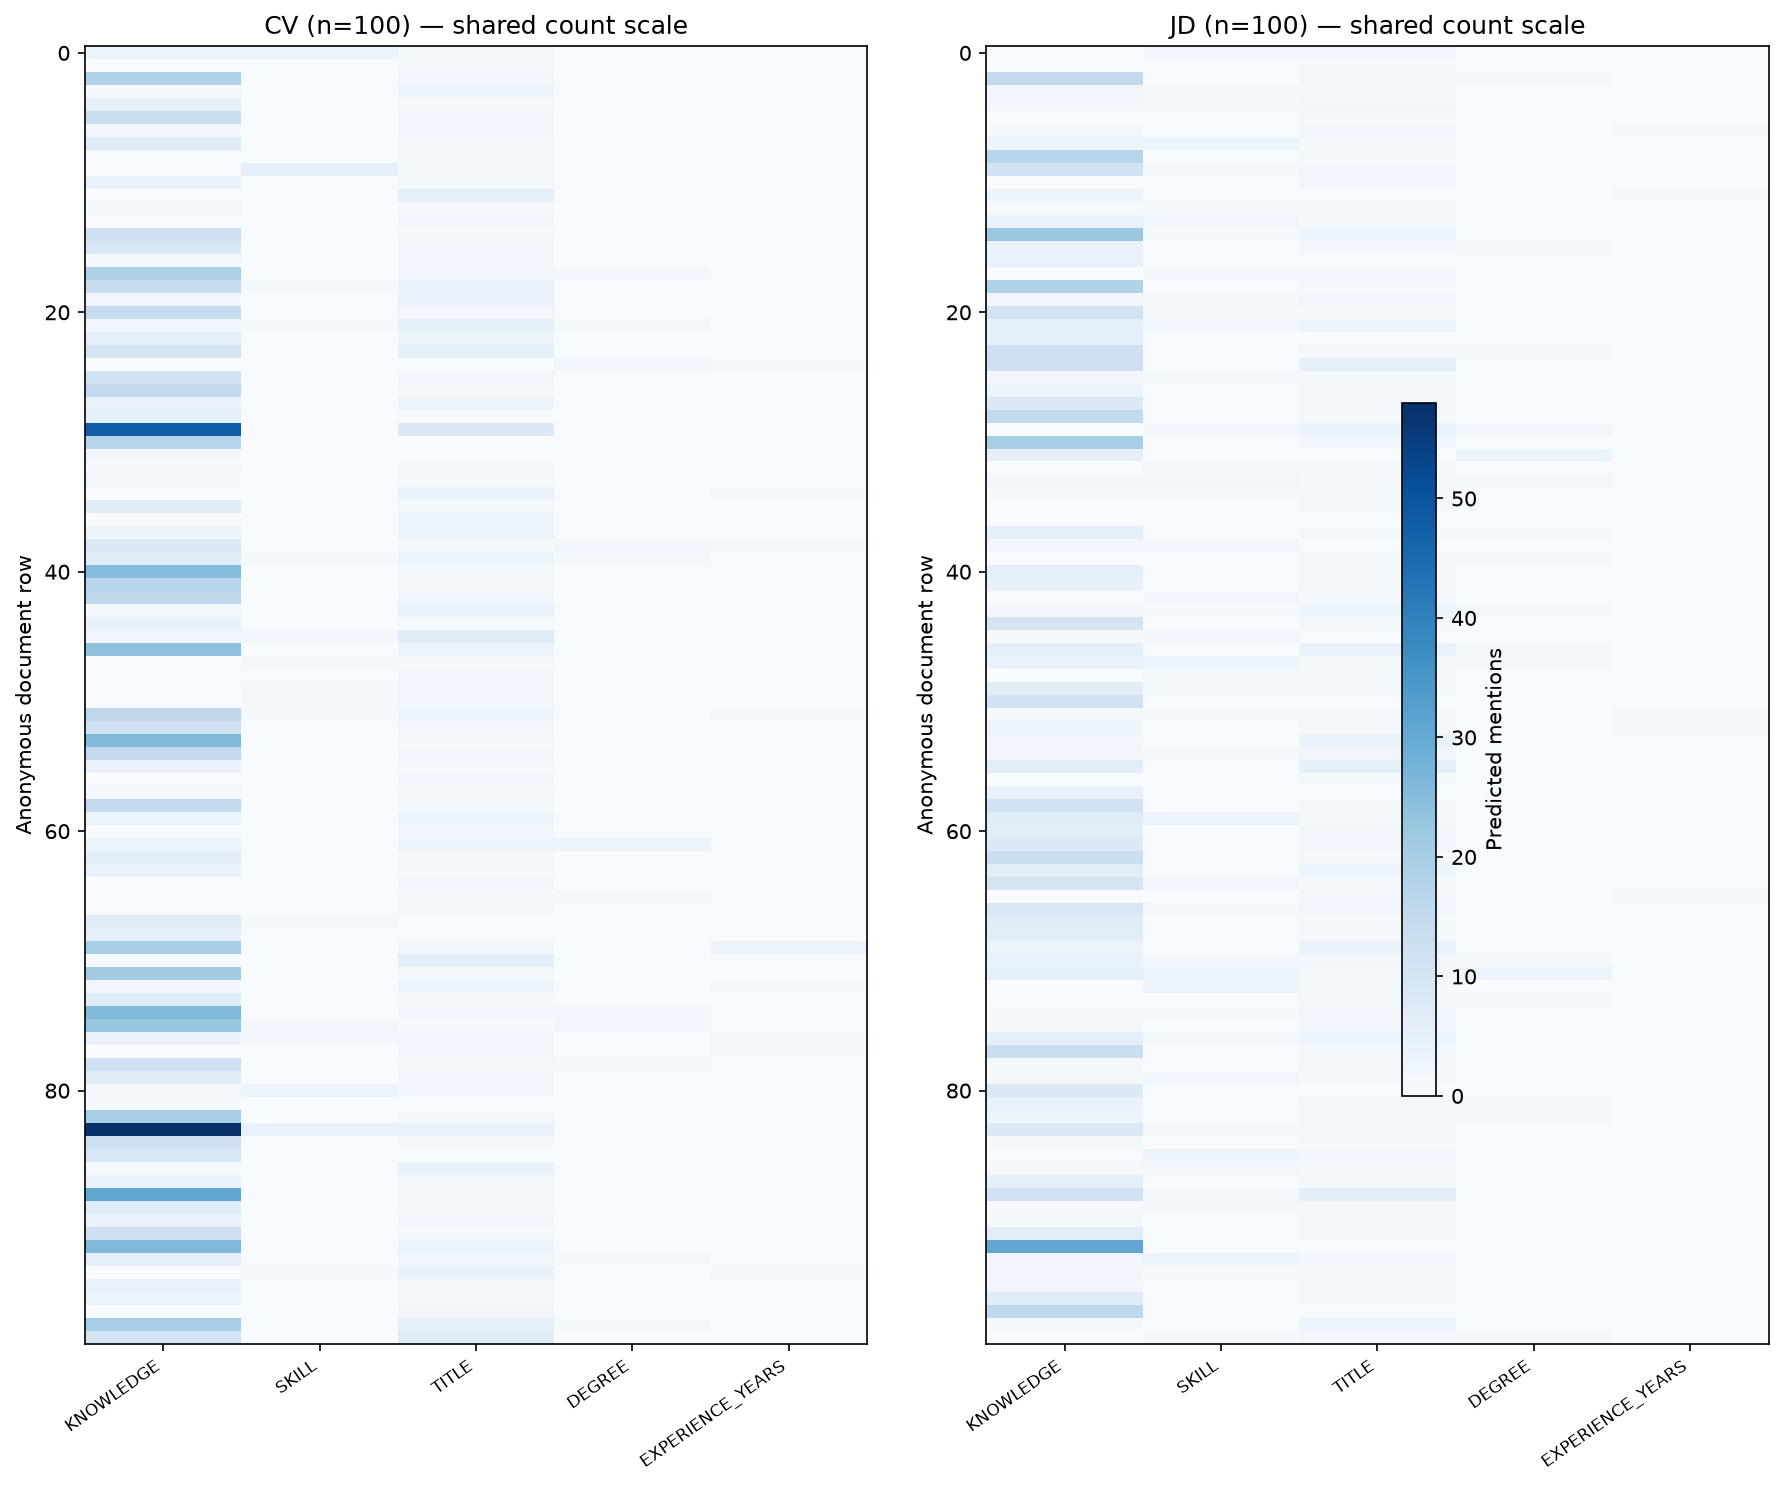

In [ ]:
display(Image(filename=str(DIRECTORY / "document-label-heatmaps.png")))
"""
Each row represents one anonymous document; each column represents an entity label. Darker blue means more predicted mentions. Both panels share the same colour scale.
These show how uneven extraction is across documents. KNOWLEDGE dominates, while DEGREE and EXPERIENCE_YEARS are sparse.
The CV and JD rows are independently ordered. Matching row numbers do not represent a labelled CV–JD pair.
"""

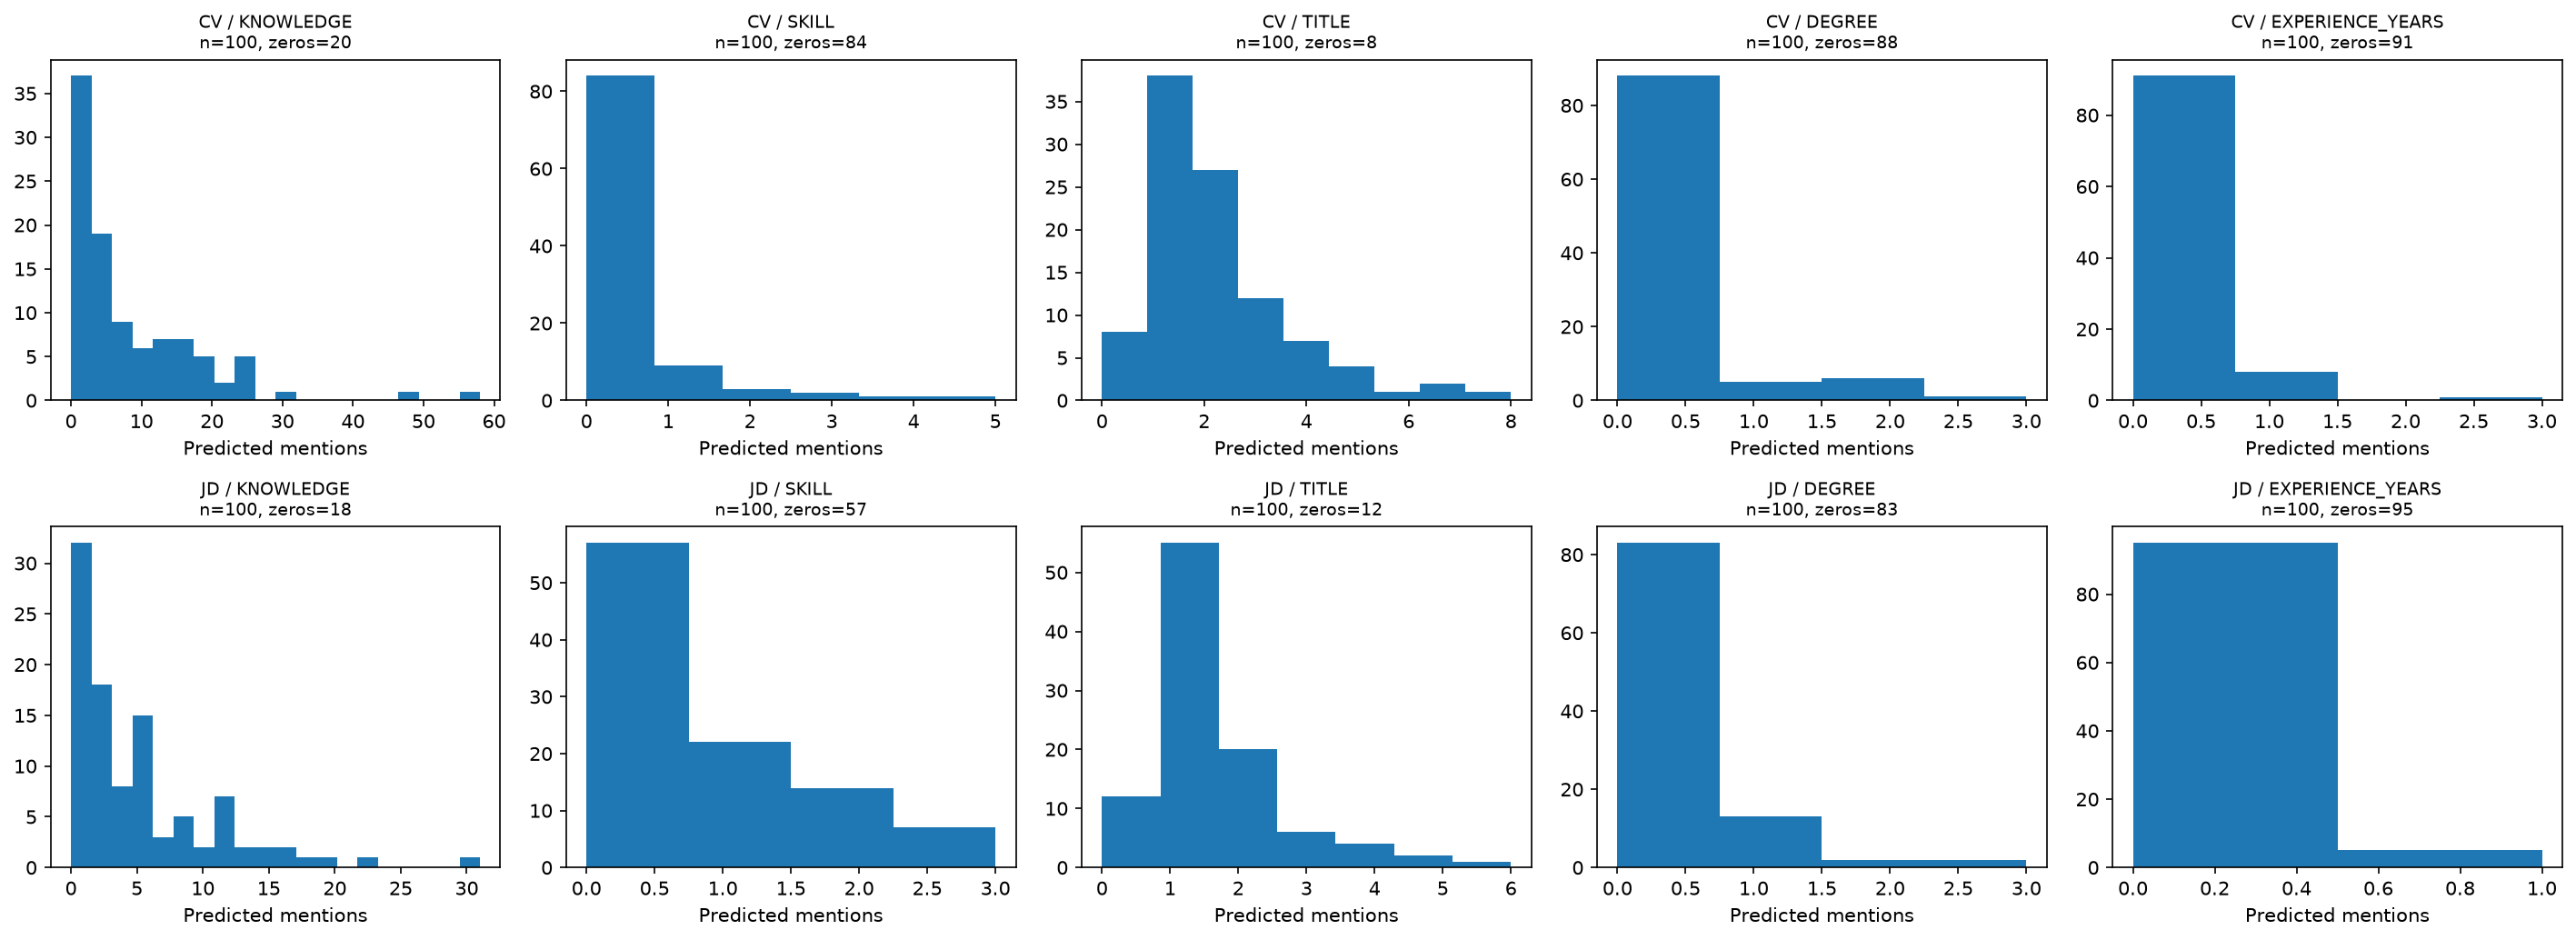

In [ ]:
display(Image(filename=str(DIRECTORY / "label-count-histograms.png")))
"""
The horizontal axis is the number of predicted mentions per document. The vertical axis is the number of documents in that count interval.
They show that:

- KNOWLEDGE has a long tail: a few documents contain many mentions.
- TITLE is returned in most documents.
- SKILL, DEGREE and EXPERIENCE_YEARS have many zero-count documents.

Crucially, the EXPERIENCE_YEARS histogram shows how many duration expressions were extracted, not the distribution of actual years. A count of three means three extracted expressions, not three years of experience.
"""

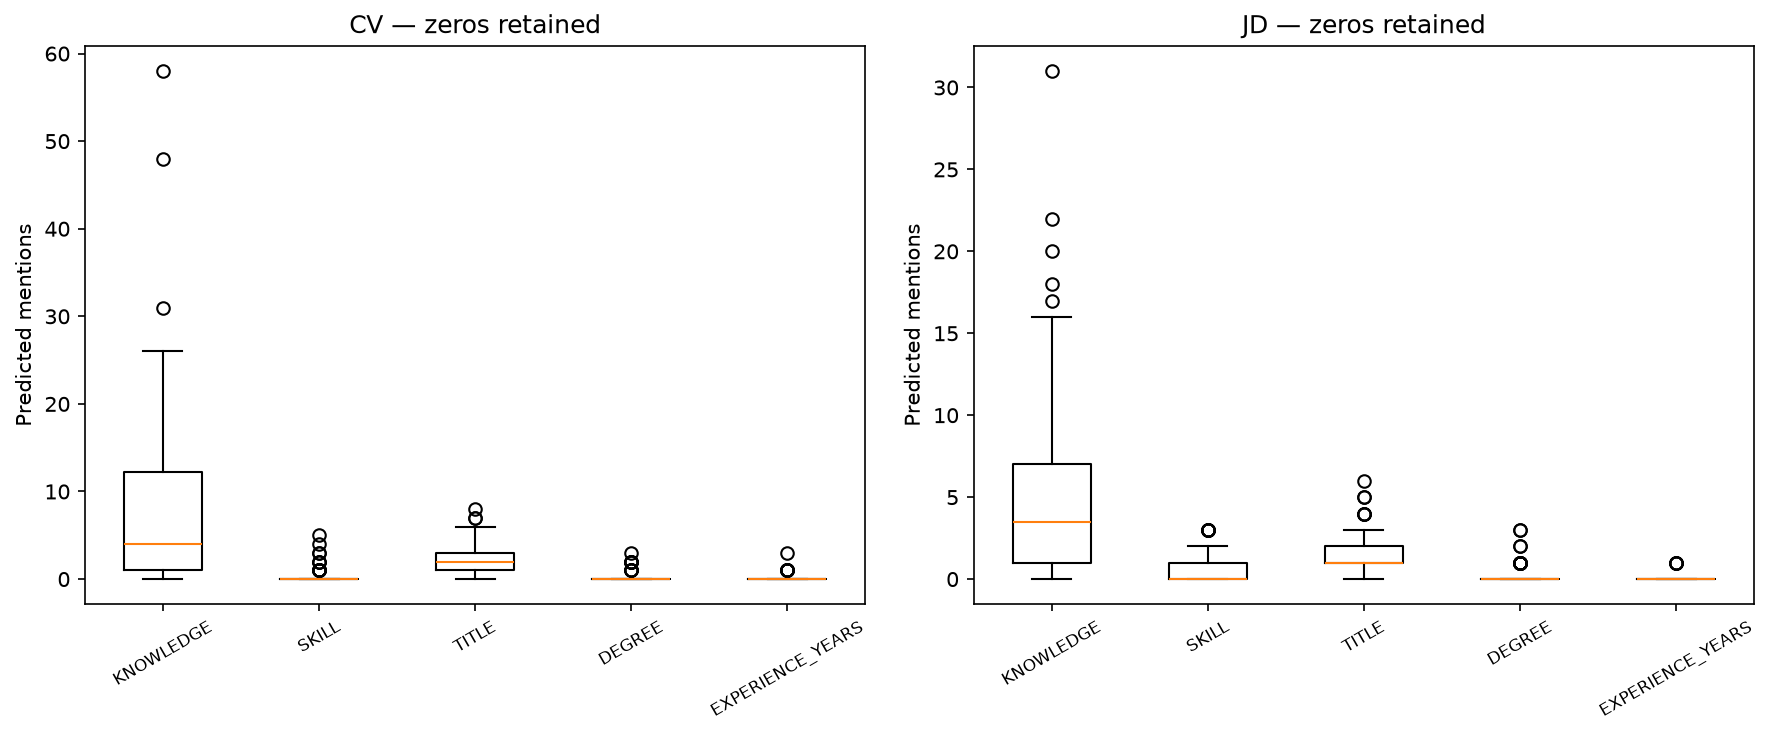

In [ ]:
display(Image(filename=str(DIRECTORY / "label-count-boxplots.png")))
"""These summarise the same counts:

- Orange line: median.
- Box: middle 50% of documents.
- Whiskers: usual spread under the boxplot convention.
- Circles: observations beyond the whiskers.

Several boxes collapse at zero because most documents have no prediction for those labels. KNOWLEDGE has the largest spread.

A high count or an outlier does not imply a better candidate.
"""

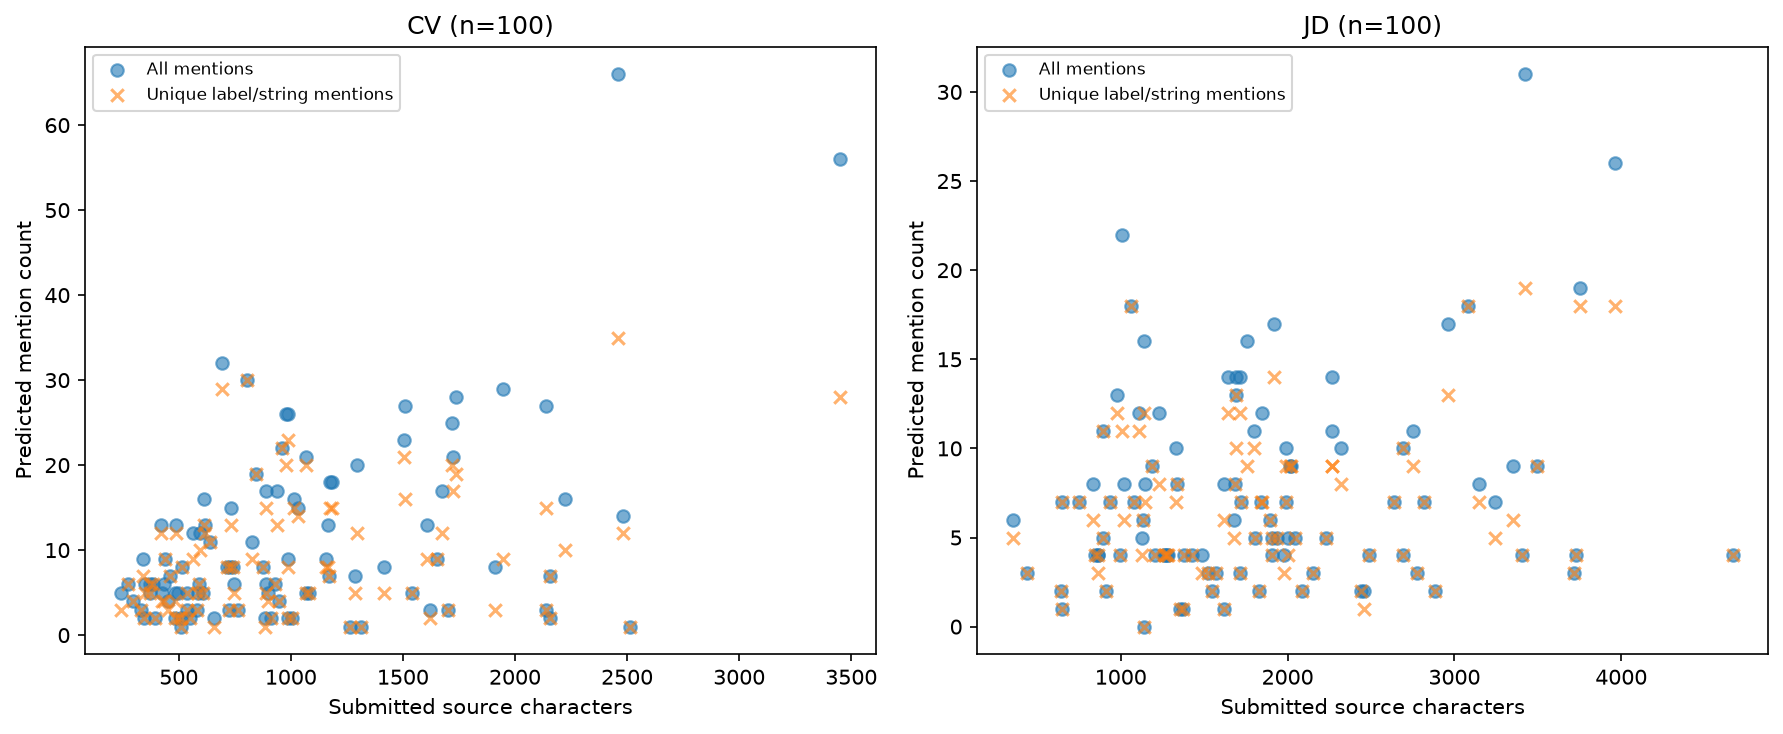

In [ ]:
display(Image(filename=str(DIRECTORY / "length-and-mention-counts.png")))
"""
Each document appears as:

- A blue circle for all extracted mentions.
- An orange cross for unique label/string mentions.

The horizontal axis measures submitted text length in characters.

A large gap between blue and orange indicates repetition. 
Longer documents sometimes contain more mentions, but length does not consistently predict entity count.

This supports avoiding raw mention totals in matching: repetition and additional text could increase a score without adding relevant evidence.
The historical extraction campaign also includes Position fields. Its counts therefore differ from the matching model’s permitted text_v2 inputs.
"""

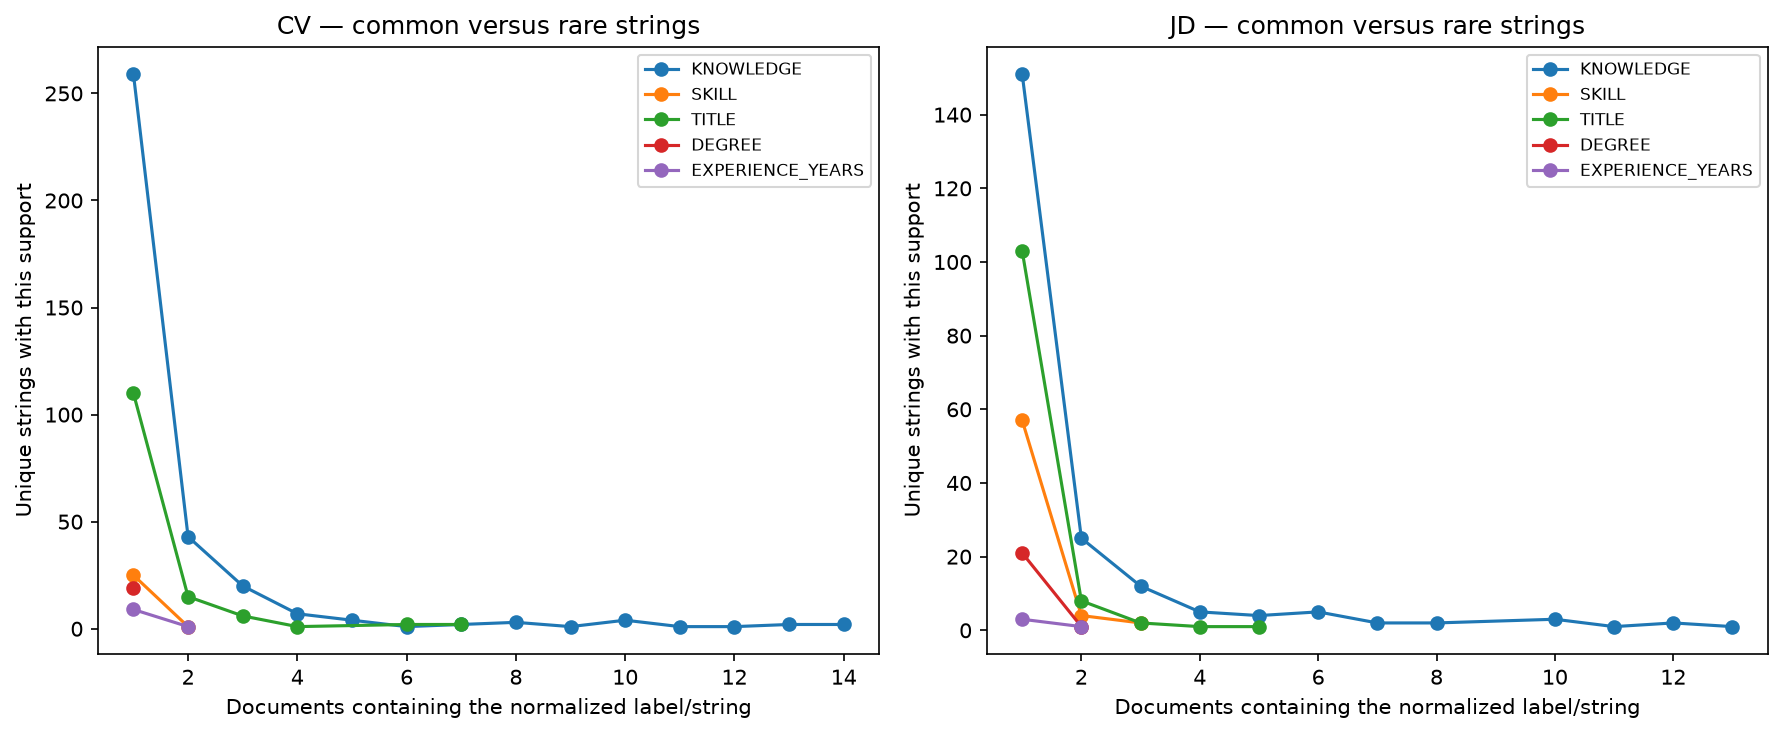

In [ ]:
display(Image(filename=str(DIRECTORY / "string-document-support.png")))
"""The horizontal axis shows how many documents contain a particular normalized string. 
The vertical axis shows how many distinct strings have that document frequency.

For example, a point at x = 2, y = 40 means 40 different strings each occur in two documents.

Most strings appear in only one document; a smaller number occur across several documents. This motivates testing IDF weighting: common concepts receive less weight than rarer ones.
However, rarity alone does not establish usefulness. Rare strings can also reflect wording differences or extraction errors. These plots use normalized strings, not fully resolved skill concepts.
"""

In [ ]:
bounded(record["labelled_overlap"])
"""
The output reports:
labelled_pairs_in_campaign: 0
reference_pairs: 600
status: no_overlap

None of the 600 reference pairs has both documents in this extraction sample. 
Consequently, this notebook cannot compare entity patterns across Good Fit, Potential Fit and No Fit labels.
"""

{
  "status": "no_overlap",
  "labelled_pairs_in_campaign": 0,
  "reference_pairs": 600,
  "interpretation": "No grade-based evidence plots when campaign has no independently labelled pairs"
}


## Proposed bounded matching model

The original X2 control remains `2 × role_match + experience_compatible + 0.999 × tfidf_scaled`. Its experience component is the existing tested text rule; the cross-encoder consumes JD/CV text, not these saved GLiNER spans.

The new experiment combines unique affirmative SKILL/KNOWLEDGE concepts with training-only IDF weights:

$$w(s)=\min(5,1+\log((N_{train}+1)/(df_{train}(s)+1)))$$
$$coverage_{idf}=\frac{\sum_{s\in J\cap C}w(s)}{\sum_{s\in J}w(s)}$$
$$score=2\,role_{match}+experience_{compatible}+0.999\,((1-\alpha)tfidf_{scaled}+\alpha coverage_{idf})$$

J and C are unique affirmative JD and CV concepts resolved through explicit vocabulary aliases; unknown phrases retain normalized-string identity. Negated or learning mentions do not prove possession. Empty J has coverage 0 plus an availability flag. Unknown training support receives weight 1. Repetition and unrelated CV concepts cannot add credit. This matching identity differs from the descriptive all-label string uniqueness above.

Alpha and representation are selected using A2 training-region development data, before frozen final evaluation. Given JD title is an independent control; CV Position and experience metadata are excluded. Report proxy relevance honestly, keep Recall@50 retrieval separate from Recall@10 shortlist ordering, and quote generic/targeted/total with query counts and paired uncertainty when available. A development result is not evidence of final-set fit improvement.


In [11]:
MODEL_RECORD = OUTPUT / "matching/entity-weighted-dev.json"
if MODEL_RECORD.is_file():
    model_record = json.loads(MODEL_RECORD.read_text())
    bounded({"status": model_record.get("status"),
             "pilot_selection": model_record.get("pilot_selection"),
             "interpretation": model_record.get("interpretation")})
else:
    bounded({"status": "pending", "reason": "Registered matching development record is not yet available"})


{
  "status": "blocked",
  "pilot_selection": null,
  "interpretation": null
}
